# IA3
IndoBERT (`indobenchmark/indobert-base-p2`) | data sizes 5 / 10 / 50 / 100% | 5 seeds.

Scales key/value activations and the feed-forward output.

In [ ]:
!pip install -q transformers==4.57.6 peft==0.18.1, datasets==5.0.1, accelerate==1.14.0
!pip install -q -U scikit-learn

import transformers, datasets, peft, accelerate, torch
print("transformers:", transformers.__version__, " (pinned)")
print("peft        :", peft.__version__, " (pinned)")
print("datasets    :", datasets.__version__, " (pinned)")
print("accelerate  :", accelerate.__version__, " (pinned)")
print("torch       :", torch.__version__, " (Colab-provided)")
print("CUDA avail  :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU         :", torch.cuda.get_device_name(0), " <- keep the same GPU type across methods")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 59.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 557.0/557.0 kB 24.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 39.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 389.2/389.2 kB 16.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 24.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 61.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import sys
sys.path.append('/content/drive/MyDrive/code')   # folder containing utils.py
from utils import *

print("Data root    :", DATA_ROOT)
print("Results file :", RESULTS_PATH)
print("Seeds        :", SEEDS)
print("Data sizes   :", DATA_SIZES)

Mounted at /content/drive
Data root    : /content/drive/MyDrive/thesis/data
Results file : /content/drive/MyDrive/thesis/results.csv
Seeds        : [42, 123, 456, 789, 2026]
Data sizes   : [100, 50, 10]


### Check data and progress

In [ ]:
validate_data_sizes()  
print()
print_status()   

 size_%                                folder  rows  actual_%_of_full  hoax_%
     10 /content/drive/MyDrive/thesis/data/10   848              10.0    50.0
     50 /content/drive/MyDrive/thesis/data/50  4244              50.0    50.0
    100    /content/drive/MyDrive/thesis/data  8486             100.0    50.0

val rows: 1212 | test rows: 2426 | full train rows: 8486
evaluation interval (steps per full-data epoch): 531
Data checks passed.

Completed seeds per (method, data size); target = 5; tag='main'
data_size  10   50   100
method                  
BitFit       5    5    5
FFT          5    5    5
IA3          0    4    5
LoRA         5    5    5
Total: 54 / 60 for methods present


### Model definition

In [4]:
from peft import IA3Config, get_peft_model, TaskType

TARGET_MODULES = r".*\.(key|value)$|.*\.\d+\.output\.dense$"
FEEDFORWARD_MODULES = r".*\.\d+\.output\.dense$"

def build_ia3_model():
    base = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=2, id2label=ID2LABEL, label2id=LABEL2ID
    )
    ia3_config = IA3Config(
        task_type=TaskType.SEQ_CLS,
        target_modules=TARGET_MODULES,
        feedforward_modules=FEEDFORWARD_MODULES,
    )
    model = get_peft_model(base, ia3_config)
    model.print_trainable_parameters()

    wrapped = [n for n, m in model.named_modules() if hasattr(m, "ia3_l")]
    assert not any("attention.output.dense" in n for n in wrapped), \
        "target_modules regex is matching the attention output projection"
    assert any(n.endswith(".key") for n in wrapped) and any(n.endswith(".value") for n in wrapped), \
        "key/value projections not targeted"
    return model

### Run all data sizes and seeds

In [ ]:
METHOD_NAME = "IA3"
LEARNING_RATE = 3e-3
TAG = "main"              
RUN_SIZES = DATA_SIZES    
RUN_SEEDS = SEEDS

In [6]:
for size in RUN_SIZES:
    for seed in RUN_SEEDS:
        run_experiment(
            method_name=METHOD_NAME,
            seed=seed,
            model_init_fn=build_ia3_model,
            learning_rate=LEARNING_RATE,
            data_size=size,
            tag=TAG,
        )

print()
print_status(tag=TAG)

[skip] IA3 data=100% seed=42 tag=main already logged
[skip] IA3 data=100% seed=123 tag=main already logged
[skip] IA3 data=100% seed=456 tag=main already logged
[skip] IA3 data=100% seed=789 tag=main already logged
[skip] IA3 data=100% seed=2026 tag=main already logged
[skip] IA3 data=50% seed=42 tag=main already logged
[skip] IA3 data=50% seed=123 tag=main already logged
[skip] IA3 data=50% seed=456 tag=main already logged
[skip] IA3 data=50% seed=789 tag=main already logged

  IA3 | data 50% | seed 2026 | tag main | lr 0.003


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

... (46 outputs left out)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at indobenchmark/indobert-base-p2 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


trainable params: 56,834 || all params: 124,499,716 || trainable%: 0.0456
trainable parameters: 56,834 / 124,499,716 (0.0456%)


Step,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
531,0.243900,0.470258,0.873762,0.873772,0.873762,0.873762
1062,0.026100,0.681861,0.874587,0.875176,0.874587,0.874538
1593,0.009300,0.804614,0.871287,0.874720,0.871287,0.870992
2124,0.004700,0.886842,0.877888,0.877991,0.877888,0.877879
2655,0.002500,0.943812,0.878713,0.879011,0.878713,0.878689
3186,0.004100,1.087156,0.878713,0.882851,0.878713,0.878384
3717,0.001100,1.074740,0.879538,0.879554,0.879538,0.879537



TEST -- Acc 0.8792 | F1 0.8792 | val F1 0.8795 | VRAM 0.823 GB | 3.8 min | 3717 steps (7 evals, best @ step 3717)

Completed seeds per (method, data size); target = 5; tag='main'
data_size  10   50   100
method                  
BitFit       5    5    5
FFT          5    5    5
IA3          5    5    5
LoRA         5    5    5
Total: 60 / 60 for methods present


### Training curves
One seed per data size (the first in `RUN_SEEDS`). X-axis is the training step; the dashed line marks the checkpoint restored for test evaluation.

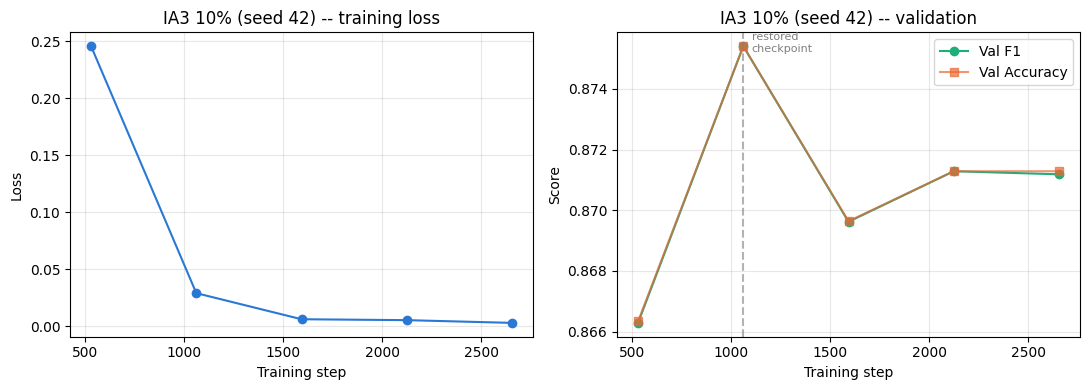

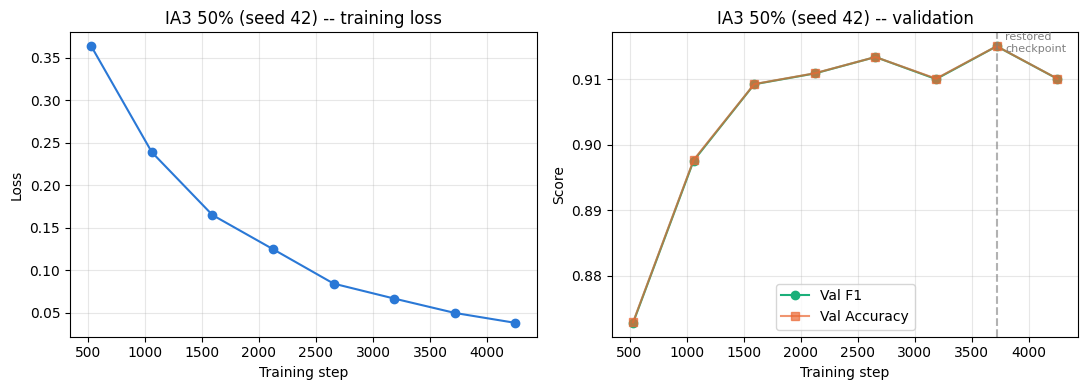

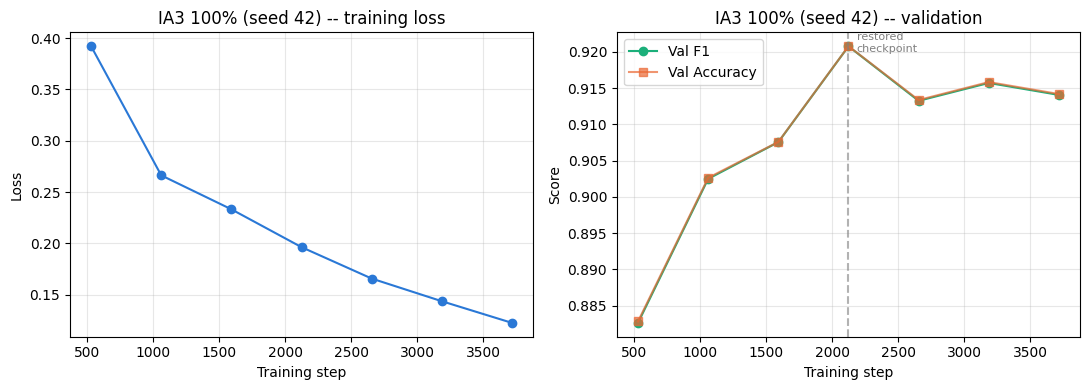

In [8]:
for size in sorted(RUN_SIZES):
    plot_training_curves(METHOD_NAME, RUN_SEEDS[0], size, TAG)

### Consistency across seeds
Validation F1 for all seeds overlaid, one chart per data size.

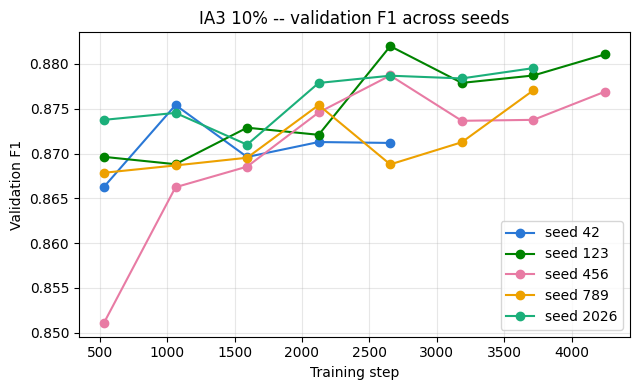

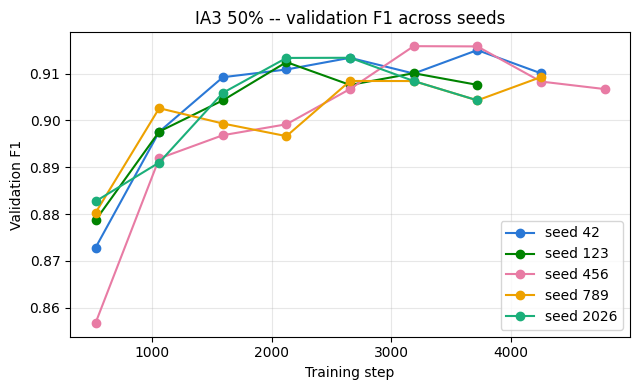

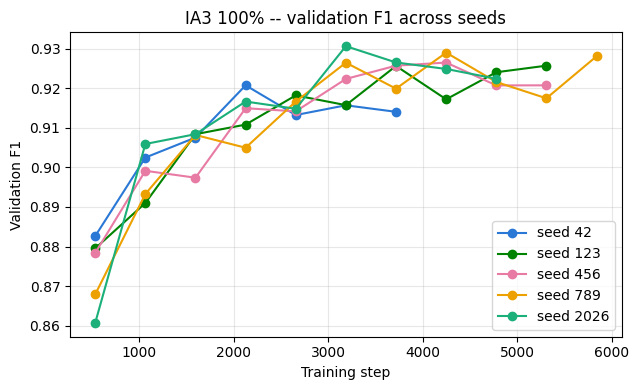

In [9]:
for size in sorted(RUN_SIZES):
    plot_seeds_overlay(METHOD_NAME, size, tag=TAG)

### Confusion matrices
Pooled over seeds, one per data size.

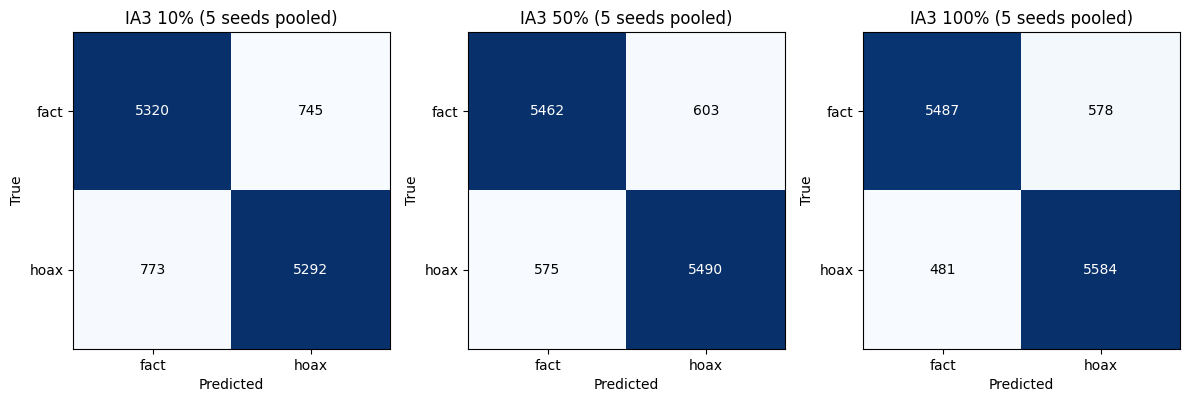

In [10]:
plot_confusion_matrices_by_size(METHOD_NAME, tag=TAG)

### Summary by data size
Mean +/- std over seeds: test vs. validation F1, generalization gap, training time.

In [ ]:
plot_method_summary(METHOD_NAME, tag=TAG)